<a href="https://colab.research.google.com/github/MonnikLuianne/wildfire-risk-piaui/blob/main/wildfire_risk_piaui.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Daily Wildfire Risk Prediction in Piauí

**Author:** Monnik Luianne Oliveira Nascimento Veloso Barbosa  
**Course:** Artificial Intelligence — Federal University of Piauí (UFPI)  
**Professor:** Dr. Pedro Almir Martins de Oliveira

**Objective.** To predict, one day in advance, whether at least one active fire will be detected in each
municipality of Piauí, using only public data, and to evaluate which information drives these predictions.

**Research question.** Do meteorological variables add predictive power beyond the seasonal and spatial pattern
of fires and the recent fire activity in each municipality? Secondary question: can an interpretable fuzzy rule
base, hand-crafted or tuned by a genetic algorithm, approach the performance of a data-driven model?

**Type of learning.** Supervised learning (binary classification). As knowledge-based comparisons, a Mamdani fuzzy
inference system and a genetic algorithm for tuning its parameters are also used.

**Links.** Repository (data and notebook): https://github.com/MonnikLuianne/wildfire-risk-piaui

## 1. Problem Description

**Context.** Vegetation fires are a recurring problem in Piauí, which includes areas of Cerrado (mainly in the south)
and Caatinga. Fire activity is concentrated in the dry season (roughly July to November) and is largely associated
with human activities such as land clearing and pasture management, favored by dry weather. Fires degrade ecosystems,
cause losses in agriculture, release greenhouse gases and produce smoke harmful to human health.

**Relevance.** Prevention and response resources (fire brigades, inspections, awareness campaigns) are limited and
must be prioritized in space and time. A daily, municipality-level risk indicator could help decide *where* to act
*tomorrow*, complementing existing fire-danger products with a transparent, data-driven evaluation.

**Potential beneficiaries.** State and municipal environmental agencies, civil defense, fire brigades and researchers
interested in fire occurrence in the Brazilian semi-arid region and Cerrado.

**Scope and limits.**
- Unit of analysis: (municipality, day), for the 224 municipalities of Piauí, from 2015 to 2025.
- Target: detection of at least one active fire by INPE's reference satellite — not the occurrence of every fire,
  nor fire size or burned area.
- Forecast horizon: one day (features use information available up to the previous day).
- Inputs: weather, season, location and recent fire activity. Human and land-use drivers (e.g., agricultural
  calendar, land cover) are not included.

## 2. Data Description

| Source | Content | Access / conditions of use |
|---|---|---|
| INPE – Programa Queimadas (BDQueimadas) | Active fire detections of the reference satellite (AQUA_M-T) in Piauí, 2015–2025: 118,402 detections, with date/time (UTC), municipality, biome, coordinates and fire radiative power | Open data, downloaded on 2026-11-11 from www.inpe.br/queimadas/bdqueimadas; source must be cited |
| NASA POWER (daily point API) | Daily weather for the municipal seat of each municipality, 2015–2025: maximum and mean temperature at 2 m (T2M_MAX, T2M), relative humidity (RH2M), precipitation (PRECTOTCORR) and wind speed at 2 m (WS2M); 900,032 rows, no missing values | Free use with acknowledgment of the NASA Langley Research Center POWER Project (power.larc.nasa.gov) |
| Brazilian municipalities dataset (IBGE-based) | IBGE code, name and coordinates of the municipal seat of the 224 municipalities | Open-source repository github.com/kelvins/municipios-brasileiros (see its license) |

Copies of the fire detections (`data/raw/`) and of the weather data (`data/processed/`) are stored in the project
repository (https://github.com/MonnikLuianne/wildfire-risk-piaui), so the notebook runs without depending on the original services.

**Modeling dataset.** 893,312 (municipality, day) rows after feature engineering (the first 30 days of 2015 are
dropped because 30-day features cannot be computed), 16 features, binary target `fire`. Classes are highly imbalanced:
4.32% of municipality-days have at least one detection (4.09% in training, 4.97% in validation, 5.13% in test).

**Known limitations.**
- *Label noise:* `fire = 0` means "no detection", not certainty of absence. The reference satellite passes once a day
  (early afternoon) and may miss small, short or cloud-covered fires (clouds are more frequent in the rainy season).
- *Spatial resolution:* NASA POWER data are gridded (≈50 km), so they represent regional rather than local conditions.
- *Coordinates:* weather is taken at the municipal seat, not the municipal centroid; municipalities differ greatly in area.
- *Biome:* each municipality is assigned the most frequent biome among its detections (approximation).
- *Time zone:* detection times are in UTC; since overpasses occur in the early afternoon, the local date is unchanged.

## 3. Setup and Reproducibility
Libraries, versions and random seed used in this notebook.

In [1]:
import sys, random
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.18
pandas: 2.2.3
numpy: 2.4.6
scikit-learn: 1.6.1


## 4. Data Loading
Active fire detections (INPE – BDQueimadas, reference satellite AQUA_M-T), Piauí, 2015–2025.

In [2]:
BASE_URL = "https://raw.githubusercontent.com/MonnikLuianne/wildfire-risk-piaui/main/data/raw"
YEARS = range(2015, 2026)

frames = []
for year in YEARS:
    df_year = pd.read_csv(f"{BASE_URL}/focos_PI_{year}.csv")
    frames.append(df_year)
    print(year, len(df_year))

fires = pd.concat(frames, ignore_index=True)
print("Total:", fires.shape)
fires.head()

2015 13839
2016 8303
2017 7657
2018 9431
2019 10894
2020 9317
2021 12745
2022 10866
2023 12957
2024 10587
2025 11806
Total: (118402, 12)


,DataHora,Satelite,Pais,Estado,Municipio,Bioma,DiaSemChuva,Precipitacao,RiscoFogo,FRP,Latitude,Longitude
0,2015/01/01 17:05:00,AQUA_M-T,Brasil,PIAUÍ,CANAVIEIRA,Cerrado,0.0,0.3,0.0,28.3,-7.268,-43.717
1,2015/01/01 17:06:00,AQUA_M-T,Brasil,PIAUÍ,PIRACURUCA,Caatinga,1.0,0.0,1.0,80.5,-3.859,-41.591
2,2015/01/01 17:06:00,AQUA_M-T,Brasil,PIAUÍ,PIRACURUCA,Caatinga,1.0,0.0,1.0,101.9,-3.861,-41.595
3,2015/01/02 16:09:00,AQUA_M-T,Brasil,PIAUÍ,BOM JESUS,Cerrado,2.0,0.0,1.0,48.1,-9.149,-44.568
4,2015/01/02 16:09:00,AQUA_M-T,Brasil,PIAUÍ,MONTE ALEGRE DO PIAUÍ,Cerrado,2.0,0.0,1.0,27.8,-9.469,-44.831


### 4.1 Municipalities of Piauí
Coordinates (municipal seat) from the IBGE-based dataset by Kelvin S. do Prado (github.com/kelvins/municipios-brasileiros).

In [3]:
import unicodedata

def normalize(name):
    name = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode()
    return name.upper().strip()

MUN_URL = "https://raw.githubusercontent.com/kelvins/municipios-brasileiros/main/csv/municipios.csv"
municipalities = pd.read_csv(MUN_URL)
municipalities = municipalities[municipalities["codigo_uf"] == 22][["codigo_ibge", "nome", "latitude", "longitude"]]
municipalities["mun_key"] = municipalities["nome"].map(normalize)
print("Municipalities in Piauí:", len(municipalities))

fires["mun_key"] = fires["Municipio"].map(normalize)
unmatched = set(fires["mun_key"]) - set(municipalities["mun_key"])
print("Unmatched names:", unmatched)

Municipalities in Piauí: 224
Unmatched names: set()


### 4.2 Weather data (NASA POWER)
Daily weather for each municipality, obtained from the NASA POWER API (power.larc.nasa.gov), 2015–2025.
Variables: max temperature (T2M_MAX), mean temperature (T2M), relative humidity (RH2M), precipitation (PRECTOTCORR) and wind speed (WS2M).

In [4]:
import requests

POWER_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"
PARAMS = ["T2M_MAX", "T2M", "RH2M", "PRECTOTCORR", "WS2M"]

def get_weather(lat, lon, start="20150101", end="20251231"):
    query = {
        "parameters": ",".join(PARAMS),
        "community": "AG",
        "latitude": lat,
        "longitude": lon,
        "start": start,
        "end": end,
        "format": "JSON",
    }
    r = requests.get(POWER_URL, params=query, timeout=120)
    r.raise_for_status()
    data = r.json()["properties"]["parameter"]
    df = pd.DataFrame(data)
    df.index = pd.to_datetime(df.index, format="%Y%m%d")
    df.index.name = "date"
    return df.replace(-999, np.nan)

# Test with Teresina
ter = municipalities[municipalities["mun_key"] == "TERESINA"].iloc[0]
teresina_test = get_weather(ter["latitude"], ter["longitude"])
print(teresina_test.shape)
print(teresina_test.isna().sum())
teresina_test.head()

(4018, 5)
T2M_MAX        0
T2M            0
RH2M           0
PRECTOTCORR    0
WS2M           0
dtype: int64


,T2M_MAX,T2M,RH2M,PRECTOTCORR,WS2M
date,,,,,
2015-01-01,31.87,27.59,66.72,0.93,1.08
2015-01-02,34.55,28.81,63.03,4.44,0.96
2015-01-03,26.37,24.36,85.66,8.81,0.92
2015-01-04,32.73,26.63,74.21,1.98,1.08
2015-01-05,32.43,27.06,71.00,4.57,1.15


In [5]:
DOWNLOAD_WEATHER = False  # set True only to re-download from the NASA POWER API (≈25 min)

if DOWNLOAD_WEATHER:
    import time
    from tqdm.auto import tqdm

    results_api = {}
    for _, row in tqdm(municipalities.iterrows(), total=len(municipalities)):
        key = row["mun_key"]
        for attempt in range(3):
            try:
                w = get_weather(row["latitude"], row["longitude"])
                w["mun_key"] = key
                results_api[key] = w
                break
            except Exception as e:
                print(key, "- attempt", attempt + 1, "failed:", e)
                time.sleep(10)
        time.sleep(1)  # be gentle with the API

    weather = pd.concat(results_api.values()).reset_index()
    print(weather.shape, "| municipalities:", weather["mun_key"].nunique())
    weather.to_csv("weather_PI_2015_2025.csv.gz", index=False, compression="gzip")
else:
    print("Skipping API download: the weather file is loaded from GitHub in Section 5.")

Skipping API download: the weather file is loaded from GitHub in Section 5.


## 5. Dataset Construction
Each row is a (municipality, day) pair. Target `fire` = 1 if at least one active fire was detected
by the reference satellite in that municipality on that day, 0 otherwise.
Note: 0 means "no detection", not certainty of absence (cloud cover, small fires and single daily overpass).

In [6]:
WEATHER_URL = "https://raw.githubusercontent.com/MonnikLuianne/wildfire-risk-piaui/main/data/processed/weather_PI_2015_2025.csv.gz"
weather = pd.read_csv(WEATHER_URL, parse_dates=["date"])
print("Weather loaded from GitHub:", weather.shape)

# One label per (municipality, day)
fires["date"] = pd.to_datetime(fires["DataHora"]).dt.normalize()
fire_days = fires[["mun_key", "date"]].drop_duplicates()
fire_days["fire"] = 1

data = weather.merge(fire_days, on=["mun_key", "date"], how="left")
data["fire"] = data["fire"].fillna(0).astype(int)

print("Dataset:", data.shape)
print("Fire days matched:", data["fire"].sum(), "of", len(fire_days))
print("Overall fire rate:", round(data["fire"].mean(), 4))
data.groupby(data["date"].dt.year)["fire"].agg(["sum", "mean"])

Weather loaded from GitHub: (900032, 7)
Dataset: (900032, 8)
Fire days matched: 38879 of 38879
Overall fire rate: 0.0432


,sum,mean
date,,
2015,3781,0.046245
2016,2962,0.036129
2017,2735,0.033452
2018,3063,0.037463
2019,3651,0.044655
2020,3111,0.037946
2021,3677,0.044973
2022,3572,0.043689
2023,4177,0.051089


## 6. Exploratory Data Analysis

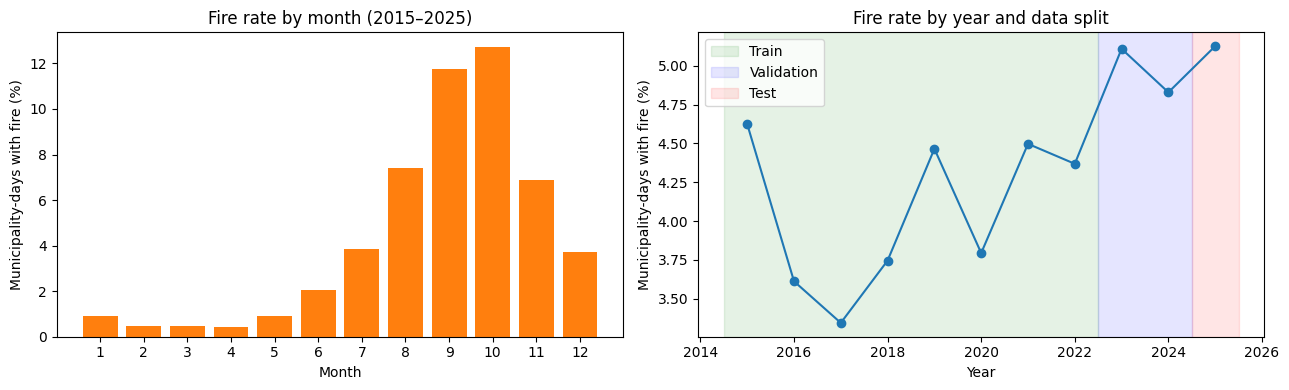

In [7]:
data["year"] = data["date"].dt.year
data["month"] = data["date"].dt.month

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

monthly = data.groupby("month")["fire"].mean() * 100
axes[0].bar(monthly.index, monthly.values, color="tab:orange")
axes[0].set_title("Fire rate by month (2015–2025)")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Municipality-days with fire (%)")
axes[0].set_xticks(range(1, 13))

yearly = data.groupby("year")["fire"].mean() * 100
axes[1].plot(yearly.index, yearly.values, marker="o")
axes[1].axvspan(2014.5, 2022.5, alpha=0.1, color="green", label="Train")
axes[1].axvspan(2022.5, 2024.5, alpha=0.1, color="blue", label="Validation")
axes[1].axvspan(2024.5, 2025.5, alpha=0.1, color="red", label="Test")
axes[1].set_title("Fire rate by year and data split")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Municipality-days with fire (%)")
axes[1].legend()

plt.tight_layout()
plt.show()

**Interpretation.** Fire activity is strongly seasonal: from January to May the fire rate stays below 1%
(rainy season), rises from June onward and peaks in September–October (~12–13% of municipality-days),
dropping again as the rains return in November–December. This indicates that seasonality must be
represented in the model (e.g., month) and that class imbalance varies throughout the year.
Across years, the rate fluctuates between ~3.3% (2017) and ~5.1% (2023, 2025) without a clear trend
in the training period, but the validation and test years (2023–2025) are among the highest.
The test set is therefore slightly harder than the training conditions. The causes of this increase
(e.g., drier years) cannot be established from these data alone.

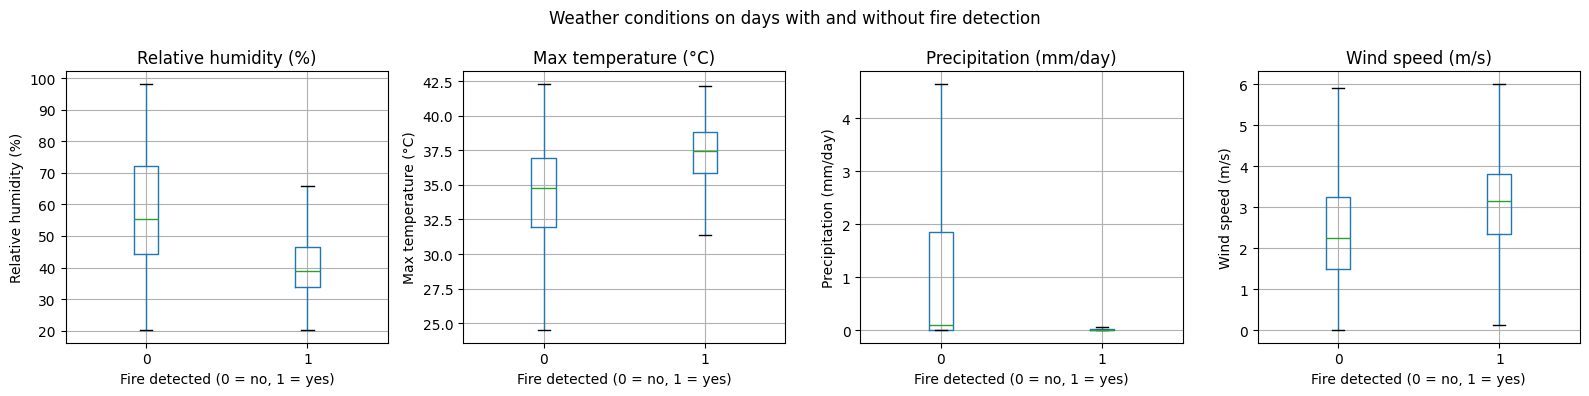

In [8]:
variables = {
    "RH2M": "Relative humidity (%)",
    "T2M_MAX": "Max temperature (°C)",
    "PRECTOTCORR": "Precipitation (mm/day)",
    "WS2M": "Wind speed (m/s)",
}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (col, label) in zip(axes, variables.items()):
    data.boxplot(column=col, by="fire", ax=ax, showfliers=False)
    ax.set_title(label)
    ax.set_xlabel("Fire detected (0 = no, 1 = yes)")
    ax.set_ylabel(label)

plt.suptitle("Weather conditions on days with and without fire detection")
plt.tight_layout()
plt.show()

**Interpretation.** Days with fire detection are drier (median relative humidity ≈40% vs ≈55%),
hotter (median max temperature ≈37.5 °C vs ≈35 °C) and windier (≈3.1 vs ≈2.3 m/s), and almost never
have rainfall. However, the distributions overlap, so no single variable separates the two classes,
which motivates a multivariate model. Same-day precipitation is weakly informative, since most
no-fire days also have zero rain; accumulated rainfall and consecutive dry days are likely better
indicators of fuel dryness and will be engineered in the next step. Part of these differences reflects
seasonality (fires occur in the dry season), so these are associations, not causal effects.
Outliers are hidden (showfliers=False) for readability.

## 7. Feature Engineering
To predict fire on day D, all features use only information available up to day D−1
(every feature is shifted by one day), preventing temporal leakage. Rolling features are computed
separately for each municipality.

| Feature | Description |
|---|---|
| `*_lag1` | Weather on the previous day |
| `rain_7d`, `rain_30d` | Accumulated precipitation over the previous 7 / 30 days (mm) |
| `dry_days` | Consecutive days with precipitation < 1 mm up to D−1 |
| `rh_mean_7d`, `tmax_mean_7d` | Mean relative humidity / max temperature over the previous 7 days |
| `fire_lag1`, `fire_7d` | Fire detected on D−1 / number of fire days in the previous 7 days |
| `month_sin`, `month_cos` | Cyclical encoding of the month |
| `latitude`, `longitude` | Municipal seat coordinates |

In [9]:
data = data.sort_values(["mun_key", "date"]).reset_index(drop=True)
g = data.groupby("mun_key")

# Previous-day weather
weather_cols = ["T2M_MAX", "T2M", "RH2M", "PRECTOTCORR", "WS2M"]
for col in weather_cols:
    data[f"{col}_lag1"] = g[col].shift(1)

# Accumulated / averaged weather (up to D-1)
data["rain_7d"] = g["PRECTOTCORR"].transform(lambda s: s.shift(1).rolling(7).sum())
data["rain_30d"] = g["PRECTOTCORR"].transform(lambda s: s.shift(1).rolling(30).sum())
data["rh_mean_7d"] = g["RH2M"].transform(lambda s: s.shift(1).rolling(7).mean())
data["tmax_mean_7d"] = g["T2M_MAX"].transform(lambda s: s.shift(1).rolling(7).mean())

# Consecutive dry days (precipitation < 1 mm), up to D-1
def consecutive_dry_days(s, threshold=1.0):
    dry = s < threshold
    return dry.groupby((~dry).cumsum()).cumsum()

data["dry_days"] = g["PRECTOTCORR"].transform(lambda s: consecutive_dry_days(s).shift(1))

# Fire history (up to D-1)
data["fire_lag1"] = g["fire"].shift(1)
data["fire_7d"] = g["fire"].transform(lambda s: s.shift(1).rolling(7).sum())

# Seasonality (cyclical month)
data["month_sin"] = np.sin(2 * np.pi * data["month"] / 12)
data["month_cos"] = np.cos(2 * np.pi * data["month"] / 12)

# Location
data = data.merge(municipalities[["mun_key", "latitude", "longitude"]], on="mun_key", how="left")

FEATURES = [f"{c}_lag1" for c in weather_cols] + [
    "rain_7d", "rain_30d", "rh_mean_7d", "tmax_mean_7d", "dry_days",
    "fire_lag1", "fire_7d", "month_sin", "month_cos", "latitude", "longitude",
]

before = len(data)
data = data.dropna(subset=FEATURES).reset_index(drop=True)
print("Rows dropped (start of the series):", before - len(data))
print("Final dataset:", data.shape)
data[FEATURES].describe().T.round(2)

Rows dropped (start of the series): 6720
Final dataset: (893312, 26)


,count,mean,std,min,25%,50%,75%,max
T2M_MAX_lag1,893312.0,34.55,3.30,23.24,32.07,34.89,37.06,42.31
T2M_lag1,893312.0,28.38,2.31,21.21,26.60,28.26,30.05,35.45
RH2M_lag1,893312.0,57.45,17.06,20.12,43.35,54.61,71.53,98.22
PRECTOTCORR_lag1,893312.0,2.09,4.91,0.00,0.00,0.08,1.71,122.08
WS2M_lag1,893312.0,2.41,1.25,0.00,1.51,2.30,3.30,7.06
rain_7d,893312.0,14.62,22.57,0.00,0.19,3.80,20.61,333.85
rain_30d,893312.0,62.53,75.53,0.00,3.78,33.67,97.68,646.09
rh_mean_7d,893312.0,57.44,16.28,25.02,44.02,54.80,70.81,95.09
tmax_mean_7d,893312.0,34.55,3.00,26.36,32.17,34.81,36.83,41.60
dry_days,893312.0,19.10,32.15,0.00,0.00,4.00,22.00,206.00


## 8. Experimental Protocol
Chronological split by whole years, preserving seasonality and preventing future information from
leaking into training:
- **Train:** 2015–2022 (model fitting)
- **Validation:** 2023–2024 (hyperparameter and decision-threshold selection)
- **Test:** 2025 (final evaluation, used only once)

In [10]:
train = data[data["year"] <= 2022]
val = data[data["year"].between(2023, 2024)]
test = data[data["year"] == 2025]

X_train, y_train = train[FEATURES], train["fire"]
X_val, y_val = val[FEATURES], val["fire"]
X_test, y_test = test[FEATURES], test["fire"]

total = len(data)
for name, part in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name:<10} {len(part):>8,} rows ({len(part)/total:.1%}) | "
          f"{part['year'].min()}–{part['year'].max()} | fire rate {part['fire'].mean():.2%}")

Train       647,808 rows (72.5%) | 2015–2022 | fire rate 4.09%
Validation  163,744 rows (18.3%) | 2023–2024 | fire rate 4.97%
Test         81,760 rows (9.2%) | 2025–2025 | fire rate 5.13%


## 9. Baselines
Three reference models, evaluated on the validation set (2023–2024):
1. **Persistence:** predicts fire on day D if fire was detected on D−1.
2. **Climatology:** fire probability = historical fire rate of the municipality in that month (computed on training data only).
3. **Logistic Regression:** linear model on all features (standardized; balanced class weights).

Because classes are highly imbalanced (≈5% positives), accuracy is not informative. The main metric is
**PR-AUC** (average precision; a random classifier scores ≈ the positive rate). Precision, recall and F1
are reported at the decision threshold that maximizes F1 on the validation set.

In [11]:
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def best_threshold(y_true, scores):
    p, r, t = precision_recall_curve(y_true, scores)
    f1 = 2 * p * r / (p + r + 1e-12)
    return t[np.argmax(f1[:-1])]

def evaluate(name, y_true, scores, threshold):
    pred = (scores >= threshold).astype(int)
    return {
        "model": name,
        "PR-AUC": average_precision_score(y_true, scores),
        "ROC-AUC": roc_auc_score(y_true, scores),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "threshold": threshold,
    }

results = []

# Baseline 1: persistence
s_pers_val = val["fire_lag1"].values
results.append(evaluate("Persistence", y_val, s_pers_val, 0.5))

# Baseline 2: climatology (training data only)
clim = train.groupby(["mun_key", "month"])["fire"].mean().rename("clim")
s_clim_val = val.join(clim, on=["mun_key", "month"])["clim"].fillna(train["fire"].mean()).values
results.append(evaluate("Climatology", y_val, s_clim_val, best_threshold(y_val, s_clim_val)))

# Baseline 3: logistic regression
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
logreg.fit(X_train, y_train)
s_lr_val = logreg.predict_proba(X_val)[:, 1]
results.append(evaluate("Logistic Regression", y_val, s_lr_val, best_threshold(y_val, s_lr_val)))

pd.DataFrame(results).round(3)

,model,PR-AUC,ROC-AUC,precision,recall,F1,threshold
0,Persistence,0.092,0.595,0.231,0.231,0.231,0.500
1,Climatology,0.308,0.868,0.319,0.448,0.373,0.171
2,Logistic Regression,0.318,0.861,0.342,0.415,0.375,0.832


**Interpretation.** Persistence is weak (PR-AUC 0.092): only ≈23% of fire days were preceded by a fire
day in the same municipality, i.e., fire detections rarely persist at the municipal level.
Climatology is a strong baseline (PR-AUC 0.308, ROC-AUC 0.868): knowing *where* and *when* already
explains a large share of fire occurrence, consistent with the strong seasonality observed in the EDA.
Logistic regression adds little over climatology (PR-AUC 0.318), possibly because a linear model cannot
capture interactions between dryness, heat and wind, and because many fires are human-ignited, so weather
only sets favorable conditions (a hypothesis, not tested here). Climatology is therefore the reference to beat.
Note: with balanced class weights the predicted probabilities are not calibrated, so the decision
threshold (0.832) is selected on the validation set.

## 10. Main Model: Random Forest
A Random Forest averages many decision trees, each trained on a bootstrap sample of the data and
considering a random subset of features at each split. Trees naturally capture non-linear interactions
(e.g., dry *and* hot *and* windy), and averaging reduces variance (overfitting) compared with a single tree.

Hyperparameters:
- `n_estimators=200`: number of trees
- `min_samples_leaf=50`: each leaf must contain at least 50 samples (limits overfitting)
- `max_features="sqrt"`: number of features considered at each split
- `max_samples=0.3`: each tree is trained on 30% of the training rows (speed and diversity)
- `class_weight="balanced_subsample"`: compensates class imbalance within each bootstrap sample

In [12]:
from sklearn.ensemble import RandomForestClassifier
import time

rf = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=50,
    max_features="sqrt",
    max_samples=0.3,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=SEED,
)

start = time.time()
rf.fit(X_train, y_train)
print(f"Training time: {time.time() - start:.0f} s")

s_rf_val = rf.predict_proba(X_val)[:, 1]
results = [r for r in results if r["model"] != "Random Forest"]  # avoid duplicates if re-run
results.append(evaluate("Random Forest", y_val, s_rf_val, best_threshold(y_val, s_rf_val)))
pd.DataFrame(results).round(3)

Training time: 154 s


,model,PR-AUC,ROC-AUC,precision,recall,F1,threshold
0,Persistence,0.092,0.595,0.231,0.231,0.231,0.500
1,Climatology,0.308,0.868,0.319,0.448,0.373,0.171
2,Logistic Regression,0.318,0.861,0.342,0.415,0.375,0.832
3,Random Forest,0.339,0.877,0.365,0.406,0.385,0.792


**Interpretation.** The Random Forest outperforms all baselines on the validation set
(PR-AUC 0.339 vs 0.308 for climatology and 0.318 for logistic regression), a ≈10% relative gain over
climatology. The larger gain compared with the linear model supports the hypothesis that non-linear
interactions between dryness, heat and wind carry predictive information. At the selected threshold,
it detects ≈41% of fire days with ≈37% precision (≈7× the precision of random alerts).
ROC-AUC differs little among models, as expected under strong class imbalance, which is why PR-AUC
is the primary metric. Whether this gain is robust, and whether it comes from weather variables
rather than location and seasonality, is examined in the next sections.

## 11. Feature Importance
Two complementary measures:
- **Impurity-based importance** (mean decrease in Gini impurity, computed during training). Fast, but
  importance is split among correlated features.
- **Permutation importance** on a random sample of 50,000 validation rows: the drop in PR-AUC when a
  feature is randomly shuffled, breaking its relationship with the target (3 repetitions).

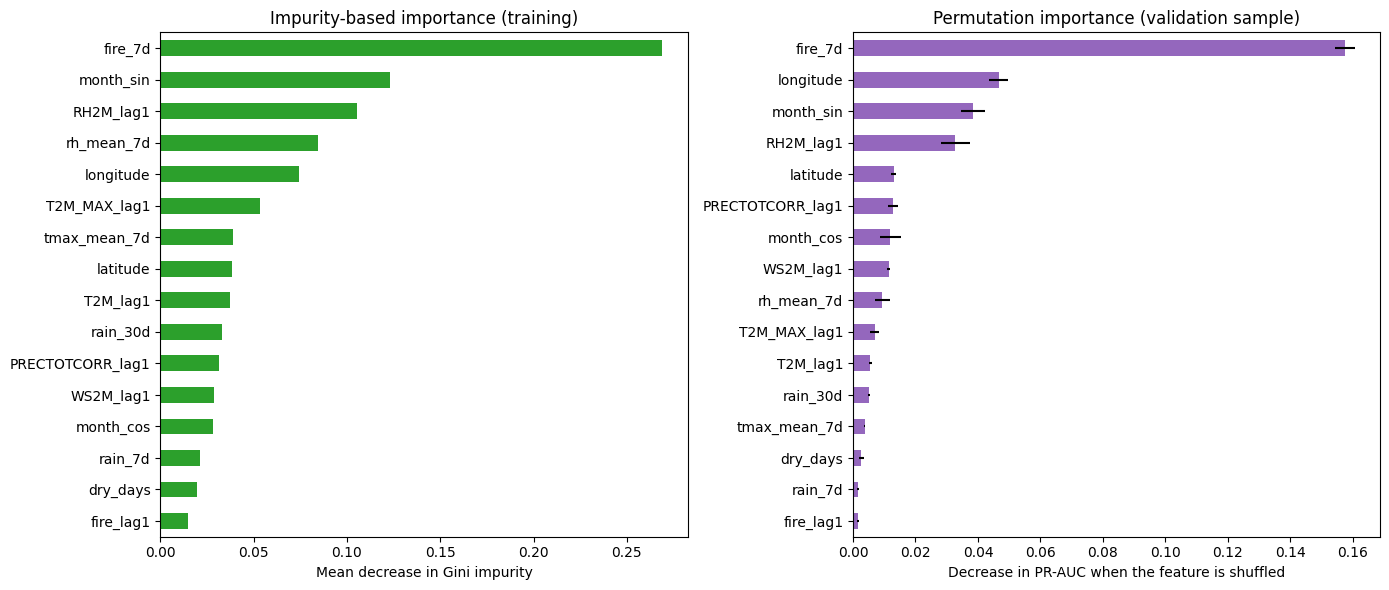

In [13]:
from sklearn.inspection import permutation_importance

mdi = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()

sample = val.sample(50000, random_state=SEED)
perm = permutation_importance(
    rf, sample[FEATURES], sample["fire"],
    scoring="average_precision", n_repeats=3, random_state=SEED,
)
perm_mean = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
perm_std = pd.Series(perm.importances_std, index=FEATURES)[perm_mean.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
mdi.plot.barh(ax=axes[0], color="tab:green")
axes[0].set_title("Impurity-based importance (training)")
axes[0].set_xlabel("Mean decrease in Gini impurity")

perm_mean.plot.barh(ax=axes[1], color="tab:purple", xerr=perm_std)
axes[1].set_title("Permutation importance (validation sample)")
axes[1].set_xlabel("Decrease in PR-AUC when the feature is shuffled")

plt.tight_layout()
plt.show()

**Interpretation.** Both measures agree that `fire_7d` (number of fire days in the municipality during
the previous week) is by far the most important feature: shuffling it reduces PR-AUC by ≈0.16, almost
half of the model's PR-AUC. In contrast, `fire_lag1` (fire on the previous day) is the least important,
consistent with the weak persistence baseline. This suggests that fires do not persist at the same place,
but municipalities go through active burning periods lasting several days (e.g., land-clearing cycles;
a hypothesis). Location and seasonality (`longitude`, `month_sin`, `latitude`, `month_cos`) come next,
consistent with the strong climatology baseline. Among weather variables, previous-day relative humidity
is the most informative. Accumulated rainfall and consecutive dry days have low importance, contrary to
our expectation from the EDA; this is likely due to redundancy with humidity, season and fire history
(permutation importance underestimates correlated features), not necessarily lack of information.
The impurity-based ranking overestimates some correlated continuous features (e.g., `rh_mean_7d`), so
permutation importance, computed on unseen data, is considered more reliable.
Since climatology does not use fire history, the gain of the Random Forest may come mainly from
`fire_7d` rather than from weather. This is tested in the ablation study below.

## 12. Ablation Study
To identify where the predictive power comes from, the same Random Forest (same hyperparameters) is
trained with different feature groups:
- **Context:** month (cyclical), latitude, longitude — *where* and *when*
- **Weather:** previous-day weather and accumulated/averaged weather variables
- **Fire history:** `fire_lag1`, `fire_7d`

Key comparisons: *Context + Weather* vs *Context only* measures the added value of weather beyond
seasonality and location (the main research question); *All features* vs *Context + Fire history*
measures the added value of weather when fire history is already known.

In [14]:
WEATHER = [f"{c}_lag1" for c in weather_cols] + ["rain_7d", "rain_30d", "rh_mean_7d", "tmax_mean_7d", "dry_days"]
FIRE_HIST = ["fire_lag1", "fire_7d"]
CONTEXT = ["month_sin", "month_cos", "latitude", "longitude"]

configs = {
    "Context only": CONTEXT,
    "Weather only": WEATHER,
    "Context + Weather": CONTEXT + WEATHER,
    "Context + Fire history": CONTEXT + FIRE_HIST,
    "All features": CONTEXT + WEATHER + FIRE_HIST,
}

def make_rf():
    return RandomForestClassifier(
        n_estimators=200, min_samples_leaf=50, max_features="sqrt", max_samples=0.3,
        class_weight="balanced_subsample", n_jobs=-1, random_state=SEED,
    )

ablation = []
for name, feats in configs.items():
    if name == "All features":
        scores = s_rf_val  # already trained in Section 10
    else:
        start = time.time()
        model = make_rf().fit(train[feats], y_train)
        scores = model.predict_proba(val[feats])[:, 1]
        print(f"{name}: trained in {time.time() - start:.0f} s")
    row = evaluate(name, y_val, scores, best_threshold(y_val, scores))
    row["n_features"] = len(feats)
    ablation.append(row)

ablation_df = pd.DataFrame(ablation).round(3)
ablation_df

Context only: trained in 56 s
Weather only: trained in 166 s
Context + Weather: trained in 133 s
Context + Fire history: trained in 54 s


,model,PR-AUC,ROC-AUC,precision,recall,F1,threshold,n_features
0,Context only,0.310,0.869,0.318,0.449,0.372,0.817,4
1,Weather only,0.197,0.803,0.207,0.352,0.261,0.655,10
2,Context + Weather,0.282,0.860,0.265,0.483,0.342,0.631,14
3,Context + Fire history,0.334,0.878,0.368,0.411,0.388,0.833,6
4,All features,0.339,0.877,0.365,0.406,0.385,0.792,16


**Interpretation.** *Context only* (PR-AUC 0.310) matches the climatology baseline (0.308), showing that
the forest learns the seasonal and spatial pattern. *Weather only* (0.197) carries signal (≈4× a random
classifier) but much less than context. Surprisingly, adding weather to context *decreases* performance
(0.282 vs 0.310). Possible explanations (hypotheses): (i) weather is largely redundant with seasonality,
adding noise rather than new information; (ii) with `max_features="sqrt"`, about one third of the splits
(C(10,3)/C(14,3) ≈ 33%) cannot consider any context feature and must use noisier weather features;
(iii) weather–fire relationships learned in 2015–2022 may not transfer to the drier validation years;
(iv) the ≈50 km resolution of NASA POWER may not capture local conditions.
Fire history adds +0.024 over context (0.334), while weather adds only +0.005 once fire history is known
(0.339). Therefore, the gain over climatology comes mainly from recent fire activity, not from weather.
At the municipality-day scale and with these data, weather variables add little predictive power beyond
location, season and recent fire history. Whether the small differences are robust is examined next.

## 13. Stability Across Random Seeds
Random Forest training is stochastic (bootstrap sampling and feature subsampling). To check whether the
differences found in the ablation study are larger than this natural variability, the four main
configurations are retrained with 5 different random seeds and evaluated on the validation set (PR-AUC).

In [15]:
RUN_STABILITY = True  # set False to skip during development (≈30 min)

SEEDS = [0, 1, 2, 3, 4]
stability_configs = ["Context only", "Context + Weather", "Context + Fire history", "All features"]

if RUN_STABILITY:
    stab_rows = []
    for seed in SEEDS:
        for name in stability_configs:
            feats = configs[name]
            model = make_rf()
            model.set_params(random_state=seed)
            model.fit(train[feats], y_train)
            scores = model.predict_proba(val[feats])[:, 1]
            stab_rows.append({"config": name, "seed": seed,
                              "PR-AUC": average_precision_score(y_val, scores)})
            print(f"Seed {seed} | {name}: {stab_rows[-1]['PR-AUC']:.4f}", flush=True)

    stab = pd.DataFrame(stab_rows)
    summary = (stab.groupby("config")["PR-AUC"]
               .agg(["mean", "std", "min", "max"])
               .loc[stability_configs].round(4))
    display(summary)
else:
    print("Stability analysis skipped (RUN_STABILITY = False).")

Seed 0 | Context only: 0.3098
Seed 0 | Context + Weather: 0.2836
Seed 0 | Context + Fire history: 0.3334
Seed 0 | All features: 0.3391
Seed 1 | Context only: 0.3096
Seed 1 | Context + Weather: 0.2835
Seed 1 | Context + Fire history: 0.3337
Seed 1 | All features: 0.3393
Seed 2 | Context only: 0.3095
Seed 2 | Context + Weather: 0.2849
Seed 2 | Context + Fire history: 0.3332
Seed 2 | All features: 0.3389
Seed 3 | Context only: 0.3096
Seed 3 | Context + Weather: 0.2838
Seed 3 | Context + Fire history: 0.3333
Seed 3 | All features: 0.3397
Seed 4 | Context only: 0.3096
Seed 4 | Context + Weather: 0.2835
Seed 4 | Context + Fire history: 0.3338
Seed 4 | All features: 0.3388


,mean,std,min,max
config,,,,
Context only,0.3096,0.0001,0.3095,0.3098
Context + Weather,0.2839,0.0006,0.2835,0.2849
Context + Fire history,0.3335,0.0002,0.3332,0.3338
All features,0.3391,0.0004,0.3388,0.3397


In [16]:
if RUN_STABILITY:
    pivot = stab.pivot(index="seed", columns="config", values="PR-AUC")
    pivot["Weather gain | context"] = pivot["Context + Weather"] - pivot["Context only"]
    pivot["Weather gain | context + fire"] = pivot["All features"] - pivot["Context + Fire history"]
    pivot["Fire-history gain | context"] = pivot["Context + Fire history"] - pivot["Context only"]
    display(pivot.round(4))

config,All features,Context + Fire history,Context + Weather,Context only,Weather gain | context,Weather gain | context + fire,Fire-history gain | context
seed,,,,,,,
0,0.3391,0.3334,0.2836,0.3098,-0.0263,0.0056,0.0236
1,0.3393,0.3337,0.2835,0.3096,-0.0261,0.0056,0.0241
2,0.3389,0.3332,0.2849,0.3095,-0.0245,0.0056,0.0238
3,0.3397,0.3333,0.2838,0.3096,-0.0257,0.0064,0.0238
4,0.3388,0.3338,0.2835,0.3096,-0.0260,0.0049,0.0243


**Interpretation.** Variability across seeds is negligible (standard deviation ≤ 0.0006), so all
differences found in the ablation study are far larger than seed-induced variation. Adding weather to
context consistently *reduces* PR-AUC (−0.026), fire history consistently increases it (+0.024), and
weather adds a small but consistent gain once fire history is known (+0.006; the worst *All features* run,
0.3388, exceeds the best *Context + Fire history* run, 0.3338). This last gain is robust but small
(≈2% relative), so it is consistent rather than practically large. Note that seeds capture model
variability only, not variability due to the evaluation period (all runs use 2023–2024); the test year
(2025) provides an independent check.
The paired comparison confirms that the sign of every difference is the same across all five seeds.

## 14. Final Evaluation on the Test Set (2025)
All models were trained on 2015–2022 and their decision thresholds were selected on the validation set
(2023–2024). The test set is used once, with no further tuning.

In [17]:
val_thr = pd.DataFrame(results).set_index("model")["threshold"]
ablation_thr = ablation_df.set_index("model")["threshold"]

test_results = []

# Baselines
test_results.append(evaluate("Persistence", y_test, test["fire_lag1"].values, 0.5))
s_clim_test = test.join(clim, on=["mun_key", "month"])["clim"].fillna(train["fire"].mean()).values
test_results.append(evaluate("Climatology", y_test, s_clim_test, val_thr["Climatology"]))
s_lr_test = logreg.predict_proba(X_test)[:, 1]
test_results.append(evaluate("Logistic Regression", y_test, s_lr_test, val_thr["Logistic Regression"]))

# Random Forest variants (same seed as in the ablation study)
test_scores = {}
for name in ["Context only", "Context + Weather", "Context + Fire history", "All features"]:
    if name == "All features":
        feats, m = FEATURES, rf  # model from Section 10
    else:
        feats = configs[name]
        m = make_rf().fit(train[feats], y_train)
    test_scores[name] = m.predict_proba(test[feats])[:, 1]
    test_results.append(evaluate(f"RF: {name}", y_test, test_scores[name], ablation_thr[name]))

test_df = pd.DataFrame(test_results).round(3)
test_df

,model,PR-AUC,ROC-AUC,precision,recall,F1,threshold
0,Persistence,0.082,0.580,0.203,0.203,0.203,0.500
1,Climatology,0.256,0.848,0.277,0.377,0.319,0.171
2,Logistic Regression,0.262,0.847,0.291,0.372,0.326,0.832
3,RF: Context only,0.257,0.850,0.275,0.377,0.318,0.817
4,RF: Context + Weather,0.233,0.841,0.241,0.430,0.309,0.631
5,RF: Context + Fire history,0.274,0.862,0.320,0.335,0.327,0.833
6,RF: All features,0.286,0.862,0.323,0.347,0.335,0.792


**Interpretation.** All models perform worse in 2025 than in validation, by a similar proportion
(e.g., climatology 0.308 → 0.256, Random Forest 0.339 → 0.286, ≈16–18% drops). Since even climatology,
which cannot overfit, drops by the same amount, this reflects a harder test year (distribution shift
between years) rather than overfitting of the Random Forest. The ranking of models is preserved:
the full Random Forest remains the best model (PR-AUC 0.286), with a gain over climatology similar to
validation (+0.030, ≈12% relative). The ablation conclusions also hold: weather alone on top of context
reduces performance (−0.024), fire history improves it (+0.017), and weather adds a small gain once fire
history is known (+0.012, larger than in validation). Recall at the validation-selected threshold dropped
more than precision (0.406 → 0.347), indicating that a fixed threshold becomes conservative in a year
with more fire activity. As the test set covers a single year, these results should be interpreted with caution.

## 15. Error Analysis (Test Set, 2025)
Error analysis of the full Random Forest at the validation-selected threshold: precision–recall curves,
confusion matrix, performance by month and biome, and performance on new outbreaks (no fire in the
municipality during the previous 7 days) versus ongoing fire activity.

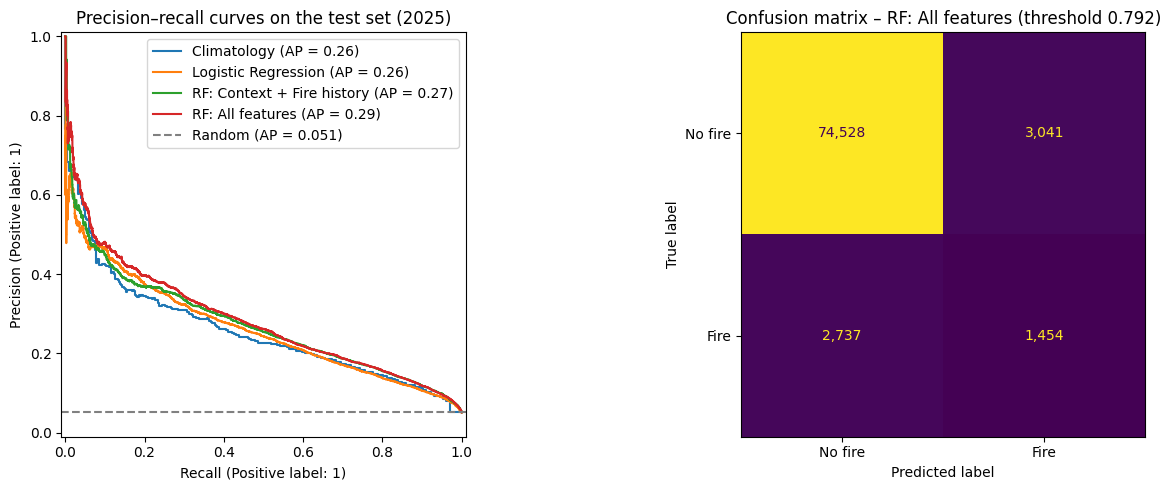

Correct alerts (TP): 1,454 | False alarms (FP): 3,041 | Missed fires (FN): 2,737 | Correct no-alert (TN): 74,528


In [18]:
from sklearn.metrics import PrecisionRecallDisplay, confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

curves = {
    "Climatology": s_clim_test,
    "Logistic Regression": s_lr_test,
    "RF: Context + Fire history": test_scores["Context + Fire history"],
    "RF: All features": test_scores["All features"],
}
for name, s in curves.items():
    PrecisionRecallDisplay.from_predictions(y_test, s, name=name, ax=axes[0])
axes[0].axhline(y_test.mean(), ls="--", color="gray", label=f"Random (AP = {y_test.mean():.3f})")
axes[0].set_title("Precision–recall curves on the test set (2025)")
axes[0].legend()

thr = ablation_thr["All features"]
pred_test = (test_scores["All features"] >= thr).astype(int)
cm = confusion_matrix(y_test, pred_test)
ConfusionMatrixDisplay(cm, display_labels=["No fire", "Fire"]).plot(
    ax=axes[1], values_format=",", colorbar=False)
axes[1].set_title(f"Confusion matrix – RF: All features (threshold {thr:.3f})")

plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Correct alerts (TP): {tp:,} | False alarms (FP): {fp:,} | "
      f"Missed fires (FN): {fn:,} | Correct no-alert (TN): {tn:,}")

**Interpretation.** The full Random Forest curve lies above the other models over most of the
recall range, especially between ≈0.1 and ≈0.6; all curves converge at high recall and remain far above
the random baseline (0.051). At the validation-selected threshold, the model issued 4,495 alerts in 2025:
1,454 were correct (35% of the 4,191 fire days) and 3,041 were false alarms (≈2 false alarms per correct
alert), while 2,737 fire days were missed.

In [19]:
# Main biome of each municipality (most frequent biome among its fire detections)
mun_biome = fires.groupby("mun_key")["Bioma"].agg(lambda s: s.mode().iloc[0])

err = test[["mun_key", "month", "fire", "fire_7d"]].copy()
err["score"] = test_scores["All features"]
err["pred"] = pred_test
err["biome"] = err["mun_key"].map(mun_biome)

def group_metrics(df, by):
    rows = []
    for key, g in df.groupby(by):
        n_fire = g["fire"].sum()
        pr_auc = average_precision_score(g["fire"], g["score"]) if n_fire > 0 else np.nan
        rows.append({
            by: key,
            "fire_days": n_fire,
            "fire_rate": g["fire"].mean(),
            "PR-AUC": pr_auc,
            "lift": pr_auc / g["fire"].mean() if n_fire > 0 else np.nan,
            "precision": precision_score(g["fire"], g["pred"], zero_division=0),
            "recall": recall_score(g["fire"], g["pred"], zero_division=0),
        })
    return pd.DataFrame(rows).round(3)

by_month = group_metrics(err, "month")
by_biome = group_metrics(err, "biome")
display(by_month)
display(by_biome)

,month,fire_days,fire_rate,PR-AUC,lift,precision,recall
0,1,88,0.013,0.039,3.045,0.000,0.000
1,2,56,0.009,0.036,4.001,0.000,0.000
2,3,37,0.005,0.054,10.105,0.000,0.000
3,4,42,0.006,0.055,8.839,0.000,0.000
4,5,101,0.015,0.129,8.839,0.000,0.000
5,6,152,0.023,0.171,7.575,0.295,0.086
6,7,346,0.050,0.350,7.034,0.367,0.500
7,8,457,0.066,0.348,5.281,0.328,0.538
8,9,690,0.103,0.357,3.480,0.284,0.517
9,10,1109,0.160,0.329,2.061,0.333,0.462


,biome,fire_days,fire_rate,PR-AUC,lift,precision,recall
0,Caatinga,2704,0.040,0.233,5.778,0.311,0.240
1,Cerrado,1487,0.102,0.375,3.684,0.334,0.542


**Interpretation.** *By month:* no alerts were issued from January to May (recall 0) even though
ranking within these months is informative (lift 3–10): with a single global threshold, low rainy-season
probabilities never reach it (324 fire days, 8%, missed). Performance is best from July to October
(recall 46–54%) and collapses in November–December (recall 16.5% and 7.6%). In 2025, the fire season
extended later than usual (November fire rate 11.4% vs ≈6.9% historically; December 5.0% vs ≈3.7%);
these two months concentrated 27% of the fire days and about one third of all missed fires. Since all
models rely on the historical seasonal pattern, this likely explains part of the performance drop of every
model in 2025. *By biome:* the model ranks Caatinga days relatively better (lift 5.8 vs 3.7), but recall is
much lower there (24% vs 54% in Cerrado), even though Caatinga holds 65% of the fire days: a single
statewide threshold favors the biome with higher fire prevalence. Biome- or region-specific thresholds are
a possible improvement. (Biome is approximated as the most frequent biome among each municipality's detections.)

In [20]:
err["situation"] = np.where(err["fire_7d"] == 0,
                            "New outbreak (no fire in previous 7 days)",
                            "Ongoing activity (fire in previous 7 days)")
by_situation = group_metrics(err, "situation")
by_situation["share_of_fire_days"] = (by_situation["fire_days"] / err["fire"].sum()).round(3)
by_situation

,situation,fire_days,fire_rate,PR-AUC,lift,precision,recall,share_of_fire_days
0,New outbreak (no fire in previous 7 days),1341,0.021,0.085,4.092,0.227,0.004,0.32
1,Ongoing activity (fire in previous 7 days),2850,0.168,0.354,2.105,0.324,0.508,0.68


**Interpretation.** New outbreaks (no fire in the municipality during the previous 7 days) account for
32% of the fire days, but the model almost never anticipates them (recall 0.4%, PR-AUC 0.085), whereas
it detects about half of the fire days with ongoing activity (recall 50.8%, PR-AUC 0.354). In practice,
the model behaves mainly as a detector of continuing fire activity, consistent with the dominance of
`fire_7d` in feature importance. This is the main limitation of the approach: anticipating where fires
start, the most valuable case for prevention, remains largely unsolved. New outbreaks are precisely where
weather information should matter most, yet the signal is weak (lift 4.1).

## 16. Fuzzy Risk Index (Knowledge-Based Model)
A Mamdani fuzzy inference system encoding expert-style rules, used as an interpretable,
knowledge-based alternative to the Random Forest. Inputs:
- `fire_7d` (recent fire activity): none / some / intense
- `rain_30d` (accumulated rainfall over 30 days, a proxy for seasonal dryness that does not depend on
  the calendar): dry / moderate / wet
- `RH2M_lag1` (previous-day relative humidity): low / medium / high
- `T2M_MAX_lag1` (previous-day maximum temperature): hot / not hot

Membership functions are trapezoidal. Their parameters were set from domain knowledge and the EDA and
checked against training-set statistics only (2015–2022); they are not tuned on validation or test data.
Only the alert threshold is selected on the validation set, as for the other models.

In [21]:
cols = ["RH2M_lag1", "rain_30d", "T2M_MAX_lag1", "fire_7d"]
train_stats = train.groupby("fire")[cols].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).round(1)
train_stats

RH2M_lag1  rain_30d  T2M_MAX_lag1  fire_7d
fire                                                 
0    0.10       37.3       0.5          29.7      0.0
     0.25       44.5       4.6          31.6      0.0
     0.50       56.1      35.9          34.6      0.0
     0.75       73.5     102.8          36.7      0.0
     0.90       84.2     174.0          38.4      1.0
1    0.10       30.8       0.0          34.0      0.0
     0.25       34.1       0.3          35.6      0.0
     0.50       39.0       2.9          37.2      1.0
     0.75       47.2      17.5          38.6      3.0
     0.90       60.5      57.8          39.5      5.0

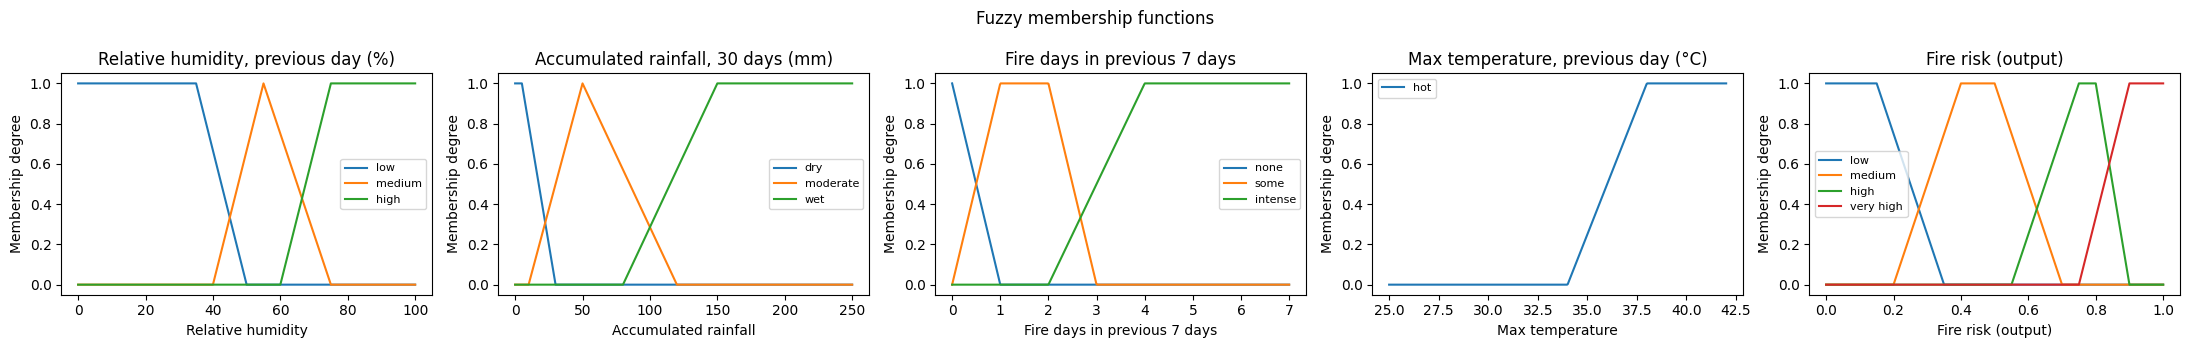

In [22]:
def trap(x, a, b, c, d):
    """Trapezoidal membership: 0 below a, rises to 1 at b, stays 1 until c, falls to 0 at d.
    a == b gives a left shoulder; c == d gives a right shoulder."""
    x = np.asarray(x, dtype=np.float32)
    left = np.ones_like(x) if b == a else np.clip((x - a) / (b - a), 0, 1)
    right = np.ones_like(x) if d == c else np.clip((d - x) / (d - c), 0, 1)
    return np.minimum(left, right)

MF = {
    "rh":    {"low": (0, 0, 35, 50), "medium": (40, 55, 55, 75), "high": (60, 75, 100, 100)},
    "rain":  {"dry": (0, 0, 5, 30), "moderate": (10, 50, 50, 120), "wet": (80, 150, 1e4, 1e4)},
    "fire":  {"none": (0, 0, 0, 1), "some": (0, 1, 2, 3), "intense": (2, 4, 7, 7)},
    "tmax":  {"hot": (34, 38, 60, 60)},
    "risk":  {"low": (0, 0, 0.15, 0.35), "medium": (0.2, 0.4, 0.5, 0.7),
              "high": (0.55, 0.75, 0.8, 0.9), "very high": (0.75, 0.9, 1, 1)},
}

panels = [
    ("rh", np.linspace(0, 100, 501), "Relative humidity, previous day (%)"),
    ("rain", np.linspace(0, 250, 501), "Accumulated rainfall, 30 days (mm)"),
    ("fire", np.linspace(0, 7, 501), "Fire days in previous 7 days"),
    ("tmax", np.linspace(25, 42, 501), "Max temperature, previous day (°C)"),
    ("risk", np.linspace(0, 1, 501), "Fire risk (output)"),
]

fig, axes = plt.subplots(1, 5, figsize=(22, 3.5))
for ax, (var, x, label) in zip(axes, panels):
    for name, params in MF[var].items():
        ax.plot(x, trap(x, *params), label=name)
    ax.set_title(label)
    ax.set_xlabel(label.split(",")[0])
    ax.set_ylabel("Membership degree")
    ax.set_ylim(-0.05, 1.05)
    ax.legend(fontsize=8)
plt.suptitle("Fuzzy membership functions")
plt.tight_layout()
plt.show()

**Membership parameters.** Initial humidity and temperature limits were adjusted once using the
training-set quantiles above (median relative humidity on fire days is 39% vs 56% on non-fire days;
median maximum temperature is 37.2 °C vs 34.6 °C). Parameters are frozen from this point on.

**Rule base** (AND = minimum, OR = maximum, NOT = 1 − μ):
1. IF recent activity is *intense* AND rainfall is *dry* THEN risk is *very high*
2. IF recent activity is *intense* AND rainfall is NOT *dry* THEN risk is *high*
3. IF recent activity is *some* AND humidity is *low* THEN risk is *high*
4. IF recent activity is *some* AND humidity is NOT *low* THEN risk is *medium*
5. IF recent activity is *none* AND rainfall is *dry* AND humidity is *low* AND temperature is *hot* THEN risk is *high*
6. IF recent activity is *none* AND rainfall is *dry* AND humidity is *low* AND temperature is NOT *hot* THEN risk is *medium*
7. IF recent activity is *none* AND rainfall is *dry* AND humidity is *medium* THEN risk is *medium*
8. IF rainfall is *wet* OR humidity is *high* THEN risk is *low*
9. IF recent activity is *none* AND rainfall is *moderate* THEN risk is *low*

Rules 5–7 address new outbreaks, where no recent fire activity is available. Rule outputs are aggregated
with the maximum and defuzzified with the centroid method.

In [23]:
from functools import reduce

U = np.linspace(0, 1, 101, dtype=np.float32)              # output universe (risk 0–1)
OUT = {name: trap(U, *p) for name, p in MF["risk"].items()}

def AND(*a): return reduce(np.minimum, a)
def OR(*a): return reduce(np.maximum, a)
def NOT(a): return 1 - a

def memberships(df):
    m = {}
    for var, col in [("rh", "RH2M_lag1"), ("rain", "rain_30d"),
                     ("fire", "fire_7d"), ("tmax", "T2M_MAX_lag1")]:
        for name, params in MF[var].items():
            m[f"{var}_{name}"] = trap(df[col].values, *params)
    return m

def rule_base(m):
    return [
        (AND(m["fire_intense"], m["rain_dry"]), "very high"),
        (AND(m["fire_intense"], NOT(m["rain_dry"])), "high"),
        (AND(m["fire_some"], m["rh_low"]), "high"),
        (AND(m["fire_some"], NOT(m["rh_low"])), "medium"),
        (AND(m["fire_none"], m["rain_dry"], m["rh_low"], m["tmax_hot"]), "high"),
        (AND(m["fire_none"], m["rain_dry"], m["rh_low"], NOT(m["tmax_hot"])), "medium"),
        (AND(m["fire_none"], m["rain_dry"], m["rh_medium"]), "medium"),
        (OR(m["rain_wet"], m["rh_high"]), "low"),
        (AND(m["fire_none"], m["rain_moderate"]), "low"),
    ]

def fuzzy_risk(df, chunk=20000):
    """Mamdani inference: min for implication, max for aggregation, centroid defuzzification."""
    rules = rule_base(memberships(df))
    n = len(df)
    scores = np.zeros(n, dtype=np.float32)
    for start in range(0, n, chunk):
        end = min(start + chunk, n)
        agg = np.zeros((end - start, len(U)), dtype=np.float32)
        for strength, label in rules:
            agg = np.maximum(agg, np.minimum(strength[start:end, None], OUT[label][None, :]))
        area = agg.sum(axis=1)
        scores[start:end] = np.where(area > 0, (agg * U).sum(axis=1) / np.maximum(area, 1e-9), 0)
    return scores

In [24]:
f_val = fuzzy_risk(val)
f_test = fuzzy_risk(test)
th_fuzzy = best_threshold(y_val, f_val)

fuzzy_eval = pd.DataFrame([
    evaluate("Fuzzy – validation", y_val, f_val, th_fuzzy),
    evaluate("Fuzzy – test", y_test, f_test, th_fuzzy),
]).round(3)
display(fuzzy_eval)

# Comparison on the test set: all days, new outbreaks, and the late season (Nov–Dec)
yt = y_test.values
new = (test["fire_7d"] == 0).values
late = test["month"].isin([11, 12]).values

candidates = {
    "Climatology": (s_clim_test, val_thr["Climatology"]),
    "RF: Context + Weather": (test_scores["Context + Weather"], ablation_thr["Context + Weather"]),
    "RF: All features": (test_scores["All features"], ablation_thr["All features"]),
    "Fuzzy": (f_test, th_fuzzy),
}
rows = []
for name, (s, thr_) in candidates.items():
    pred = (s >= thr_).astype(int)
    rows.append({
        "model": name,
        "PR-AUC (all)": average_precision_score(yt, s),
        "PR-AUC (new outbreaks)": average_precision_score(yt[new], s[new]),
        "recall (new outbreaks)": recall_score(yt[new], pred[new]),
        "precision (new outbreaks)": precision_score(yt[new], pred[new], zero_division=0),
        "recall (Nov–Dec)": recall_score(yt[late], pred[late]),
    })
comparison = pd.DataFrame(rows).round(3)
comparison

,model,PR-AUC,ROC-AUC,precision,recall,F1,threshold
0,Fuzzy – validation,0.228,0.794,0.401,0.285,0.333,0.745
1,Fuzzy – test,0.193,0.795,0.334,0.226,0.270,0.745


,model,PR-AUC (all),PR-AUC (new outbreaks),recall (new outbreaks),precision (new outbreaks),recall (Nov–Dec)
0,Climatology,0.256,0.086,0.120,0.118,0.170
1,RF: Context + Weather,0.233,0.079,0.195,0.106,0.259
2,RF: All features,0.286,0.085,0.004,0.227,0.137
3,Fuzzy,0.193,0.048,0.000,0.000,0.144


**Interpretation.** The fuzzy index reaches PR-AUC 0.193 on the test set (≈3.8× a random classifier),
below climatology (0.256) and the full Random Forest (0.286). Nevertheless, with only nine hand-written
rules and no training, it recovers about two thirds of the Random Forest's PR-AUC, with similar precision
at its selected threshold (0.334 vs 0.323) but lower recall. Its validation-to-test drop (−15%) mirrors
that of the other models.
Neither specific hypothesis was confirmed. (i) *New outbreaks:* the fuzzy index never issued alerts for
them (recall 0). This is structural: without recent fire activity the rule base can reach at most the
*high* risk set (centroid ≈0.73), while the threshold selected on validation (0.745) lies in the
*very high* region, reachable only with intense recent activity. As with the Random Forest, recent fire
activity dominates the risk scale. No model anticipates new outbreaks well (PR-AUC ≈0.05–0.09 for a
≈2% fire rate). (ii) *Late season:* replacing the calendar month with 30-day rainfall did not improve
recall in November–December (0.144 vs 0.137 for the full Random Forest and 0.170 for climatology).
Interestingly, the Random Forest with context and weather but without fire history achieved the highest
recall both for new outbreaks (0.195) and in November–December (0.259), suggesting that weather helps
somewhat when fire history is absent or the season departs from the usual pattern. However, it also issues
more alerts overall (lower threshold), and its PR-AUC on new outbreaks is not higher (0.079), so this is
an indication rather than a firm conclusion.
A natural extension is to learn the membership parameters from data (e.g., with a genetic algorithm or
ANFIS), combining interpretability with data-driven tuning.

## 17. Genetic Algorithm Tuning of the Fuzzy Index
As an extension, a genetic algorithm (GA) tunes the membership parameters of the fuzzy system while
keeping the rule base unchanged, preserving interpretability. *Transparency note:* this extension was
added after evaluating the hand-crafted fuzzy index on the test set; the GA itself uses only training
data (fitness) and validation data (threshold), and the test set is used once, as for all other models.
The hand-crafted version is kept for comparison.

- **Chromosome:** 9 real-valued genes — limits of *low* humidity, *dry* rainfall, *hot* temperature and
  *intense* recent activity, plus a shift of the *high* output set.
- **Fitness:** PR-AUC of the fuzzy index on a random sample of 100,000 training rows.
- **Operators:** tournament selection (k = 3), arithmetic crossover, Gaussian mutation (probability 0.2
  per gene, σ = 10% of the gene range), elitism (2 individuals), and a repair step that enforces
  parameter ordering. Population 30, 25 generations.
- **Seeding:** the hand-crafted parameters are included in the initial population.

In [25]:
import copy

GENE_NAMES = ["rh_low_full", "rh_low_zero", "rain_dry_full", "rain_dry_zero",
              "hot_start", "hot_full", "intense_start", "intense_full", "high_out_shift"]
GENE_BOUNDS = np.array([
    [20, 45], [40, 65],      # humidity 'low'
    [0, 20], [15, 60],       # rainfall 'dry'
    [30, 37], [33, 40],      # temperature 'hot'
    [1, 3], [2, 5],          # recent activity 'intense'
    [-0.20, 0.15],           # shift of the 'high' output set
], dtype=float)
HAND_GENES = np.array([35, 50, 5, 30, 34, 38, 2, 4, 0.0])

def repair(g):
    g = np.clip(g, GENE_BOUNDS[:, 0], GENE_BOUNDS[:, 1])
    g[1] = max(g[1], g[0] + 2)
    g[3] = max(g[3], g[2] + 2)
    g[5] = max(g[5], g[4] + 0.5)
    g[7] = max(g[7], g[6] + 0.5)
    return g

def genes_to_mf(g):
    mf = copy.deepcopy(MF)
    mf["rh"]["low"] = (0, 0, g[0], g[1])
    mf["rain"]["dry"] = (0, 0, g[2], g[3])
    mf["tmax"]["hot"] = (g[4], g[5], 60, 60)
    mf["fire"]["intense"] = (g[6], g[7], 7, 7)
    mf["risk"]["high"] = tuple(min(v + g[8], 1.0) for v in (0.55, 0.75, 0.8, 0.9))
    return mf

def fuzzy_risk_mf(df, mf, chunk=20000):
    """Same Mamdani inference as fuzzy_risk, but with a given set of membership functions."""
    out = {name: trap(U, *p) for name, p in mf["risk"].items()}
    m = {}
    for var, col in [("rh", "RH2M_lag1"), ("rain", "rain_30d"),
                     ("fire", "fire_7d"), ("tmax", "T2M_MAX_lag1")]:
        for name, params in mf[var].items():
            m[f"{var}_{name}"] = trap(df[col].values, *params)
    rules = rule_base(m)
    n = len(df)
    scores = np.zeros(n, dtype=np.float32)
    for start in range(0, n, chunk):
        end = min(start + chunk, n)
        agg = np.zeros((end - start, len(U)), dtype=np.float32)
        for strength, label in rules:
            agg = np.maximum(agg, np.minimum(strength[start:end, None], out[label][None, :]))
        area = agg.sum(axis=1)
        scores[start:end] = np.where(area > 0, (agg * U).sum(axis=1) / np.maximum(area, 1e-9), 0)
    return scores

ga_sample = train.sample(100_000, random_state=SEED)
y_ga = ga_sample["fire"].values

def fitness(g):
    return average_precision_score(y_ga, fuzzy_risk_mf(ga_sample, genes_to_mf(g)))

# Sanity check: the hand-crafted parameters must reproduce the original fuzzy index
assert np.allclose(fuzzy_risk_mf(val, genes_to_mf(HAND_GENES)), f_val, atol=1e-5)
print("Hand-crafted fitness (training sample):", round(fitness(HAND_GENES), 4))

Hand-crafted fitness (training sample): 0.2427


Gen  1 | best 0.2625 | mean 0.2460 | 14 s
Gen  2 | best 0.2669 | mean 0.2517 | 28 s
Gen  3 | best 0.2669 | mean 0.2572 | 41 s
Gen  4 | best 0.2673 | mean 0.2600 | 55 s
Gen  5 | best 0.2749 | mean 0.2640 | 69 s
Gen  6 | best 0.2749 | mean 0.2675 | 83 s
Gen  7 | best 0.2779 | mean 0.2703 | 97 s
Gen  8 | best 0.2782 | mean 0.2740 | 110 s
Gen  9 | best 0.2788 | mean 0.2757 | 124 s
Gen 10 | best 0.2791 | mean 0.2765 | 138 s
Gen 11 | best 0.2806 | mean 0.2774 | 152 s
Gen 12 | best 0.2808 | mean 0.2788 | 165 s
Gen 13 | best 0.2811 | mean 0.2793 | 179 s
Gen 14 | best 0.2817 | mean 0.2797 | 193 s
Gen 15 | best 0.2821 | mean 0.2806 | 206 s
Gen 16 | best 0.2834 | mean 0.2813 | 220 s
Gen 17 | best 0.2841 | mean 0.2815 | 234 s
Gen 18 | best 0.2846 | mean 0.2824 | 248 s
Gen 19 | best 0.2852 | mean 0.2831 | 262 s
Gen 20 | best 0.2852 | mean 0.2838 | 276 s
Gen 21 | best 0.2852 | mean 0.2838 | 290 s
Gen 22 | best 0.2853 | mean 0.2842 | 304 s
Gen 23 | best 0.2853 | mean 0.2846 | 318 s
Gen 24 | best 0.28

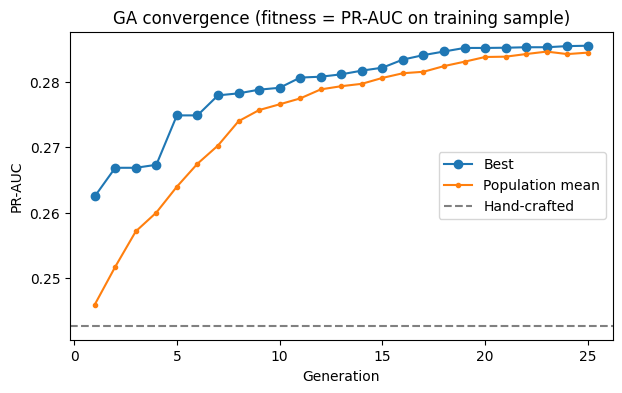

,hand-crafted,GA-tuned
rh_low_full,35.0,32.01
rh_low_zero,50.0,64.32
rain_dry_full,5.0,10.91
rain_dry_zero,30.0,55.00
hot_start,34.0,35.90
hot_full,38.0,39.98
intense_start,2.0,1.03
intense_full,4.0,4.14
high_out_shift,0.0,-0.18


In [26]:
POP, GENS, ELITE, TOUR, P_MUT = 30, 25, 2, 3, 0.2
lo, hi = GENE_BOUNDS[:, 0], GENE_BOUNDS[:, 1]
sigma = 0.1 * (hi - lo)
rng = np.random.default_rng(SEED)

pop = [repair(rng.uniform(lo, hi)) for _ in range(POP - 1)] + [HAND_GENES.copy()]
fit = np.array([fitness(g) for g in pop])

def tournament():
    idx = rng.choice(POP, TOUR, replace=False)
    return pop[idx[np.argmax(fit[idx])]]

history = []
start = time.time()
for gen in range(GENS):
    order = np.argsort(fit)[::-1]
    new_pop = [pop[i].copy() for i in order[:ELITE]]
    new_fit = [fit[i] for i in order[:ELITE]]
    while len(new_pop) < POP:
        p1, p2 = tournament(), tournament()
        w = rng.uniform(size=len(lo))
        child = w * p1 + (1 - w) * p2                                   # arithmetic crossover
        child = child + (rng.random(len(lo)) < P_MUT) * rng.normal(0, sigma)  # Gaussian mutation
        child = repair(child)
        new_pop.append(child)
        new_fit.append(fitness(child))
    pop, fit = new_pop, np.array(new_fit)
    history.append({"generation": gen + 1, "best": fit.max(), "mean": fit.mean()})
    print(f"Gen {gen + 1:2d} | best {fit.max():.4f} | mean {fit.mean():.4f} | {time.time() - start:.0f} s",
          flush=True)

best_genes = pop[int(np.argmax(fit))]
history = pd.DataFrame(history)

plt.figure(figsize=(7, 4))
plt.plot(history["generation"], history["best"], marker="o", label="Best")
plt.plot(history["generation"], history["mean"], marker=".", label="Population mean")
plt.axhline(fitness(HAND_GENES), ls="--", color="gray", label="Hand-crafted")
plt.title("GA convergence (fitness = PR-AUC on training sample)")
plt.xlabel("Generation")
plt.ylabel("PR-AUC")
plt.legend()
plt.show()

pd.DataFrame({"hand-crafted": HAND_GENES, "GA-tuned": best_genes}, index=GENE_NAMES).round(2)

**Interpretation.** The GA improved training fitness from 0.243 (hand-crafted) to 0.286 (+18%). Even the
best random individual of the first generation outperformed the hand-crafted parameters, which were thus
far from optimal. The population converged after ≈19 generations (mean close to best), so further
generations are unlikely to help.
The tuned parameters are informative: *low* humidity was widened (zero membership at 64% instead of 50%),
*dry* rainfall was widened (55 mm instead of 30 mm), *hot* became stricter (full membership at 40 °C), any
recent fire activity (≥1 day) is now largely treated as *intense*, and the *high* output set was shifted
down by 0.18. Contrary to our expectation that the GA would raise the *high* set to help new outbreaks
reach the alert threshold, it lowered it, increasing the separation between municipalities with and without
recent activity. The GA thus independently reinforced the reliance on fire history found by the Random
Forest and the ablation study.
Several genes ended at or near their bounds (e.g., 64.3 of 65 for *low* humidity, 39.98 of 40 °C for *hot*,
1.03 of 1 for *intense*), suggesting that better fitness might exist beyond them. The bounds were chosen to
keep fuzzy sets linguistically plausible (e.g., 64% relative humidity is hardly "low" for an expert),
which illustrates a trade-off between accuracy and interpretability.

In [27]:
mf_ga = genes_to_mf(best_genes)
fga_val = fuzzy_risk_mf(val, mf_ga)
fga_test = fuzzy_risk_mf(test, mf_ga)
th_fga = best_threshold(y_val, fga_val)

display(pd.DataFrame([
    evaluate("Fuzzy hand-crafted – validation", y_val, f_val, th_fuzzy),
    evaluate("Fuzzy GA – validation", y_val, fga_val, th_fga),
    evaluate("Fuzzy hand-crafted – test", y_test, f_test, th_fuzzy),
    evaluate("Fuzzy GA – test", y_test, fga_test, th_fga),
]).round(3))

candidates["Fuzzy (GA)"] = (fga_test, th_fga)
rows = []
for name, (s, thr_) in candidates.items():
    pred = (s >= thr_).astype(int)
    rows.append({
        "model": name,
        "PR-AUC (all)": average_precision_score(yt, s),
        "PR-AUC (new outbreaks)": average_precision_score(yt[new], s[new]),
        "recall (new outbreaks)": recall_score(yt[new], pred[new]),
        "precision (new outbreaks)": precision_score(yt[new], pred[new], zero_division=0),
        "recall (Nov–Dec)": recall_score(yt[late], pred[late]),
    })
comparison_ga = pd.DataFrame(rows).round(3)
comparison_ga

,model,PR-AUC,ROC-AUC,precision,recall,F1,threshold
0,Fuzzy hand-crafted – validation,0.228,0.794,0.401,0.285,0.333,0.745
1,Fuzzy GA – validation,0.271,0.818,0.347,0.386,0.365,0.606
2,Fuzzy hand-crafted – test,0.193,0.795,0.334,0.226,0.270,0.745
3,Fuzzy GA – test,0.226,0.817,0.293,0.321,0.306,0.606


,model,PR-AUC (all),PR-AUC (new outbreaks),recall (new outbreaks),precision (new outbreaks),recall (Nov–Dec)
0,Climatology,0.256,0.086,0.120,0.118,0.170
1,RF: Context + Weather,0.233,0.079,0.195,0.106,0.259
2,RF: All features,0.286,0.085,0.004,0.227,0.137
3,Fuzzy,0.193,0.048,0.000,0.000,0.144
4,Fuzzy (GA),0.226,0.047,0.000,0.000,0.207


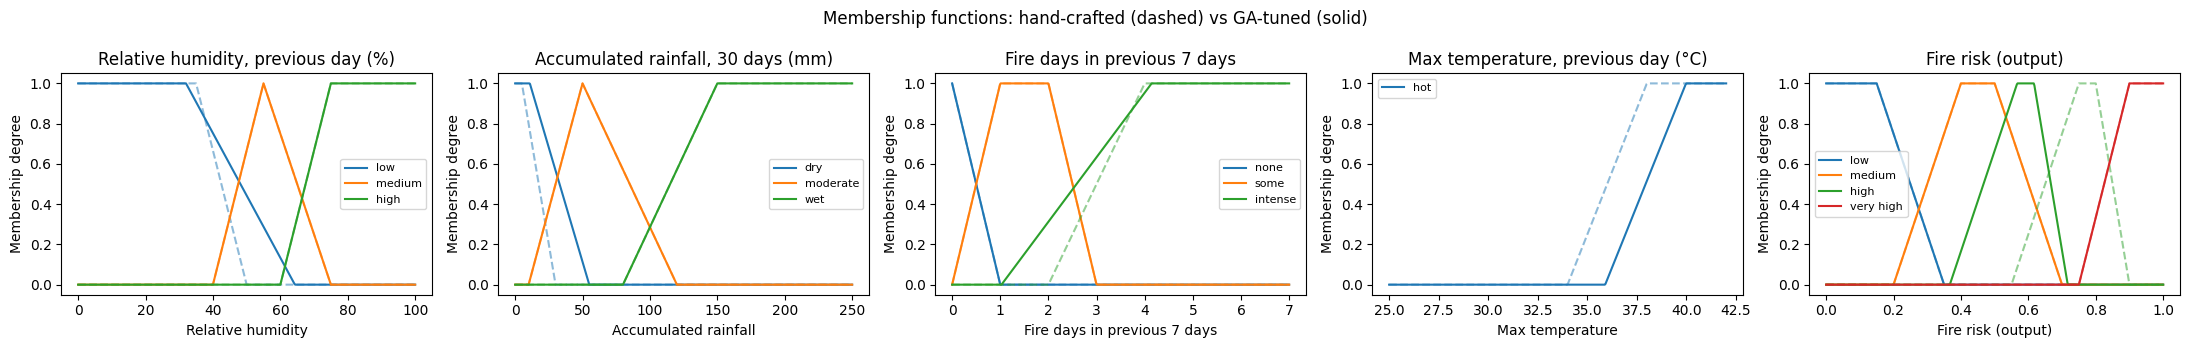

In [28]:
fig, axes = plt.subplots(1, 5, figsize=(22, 3.5))
for ax, (var, x, label) in zip(axes, panels):
    for i, (name, params) in enumerate(MF[var].items()):
        color = f"C{i}"
        ax.plot(x, trap(x, *params), ls="--", color=color, alpha=0.5)
        ax.plot(x, trap(x, *mf_ga[var][name]), color=color, label=name)
    ax.set_title(label)
    ax.set_xlabel(label.split(",")[0])
    ax.set_ylabel("Membership degree")
    ax.set_ylim(-0.05, 1.05)
    ax.legend(fontsize=8)
plt.suptitle("Membership functions: hand-crafted (dashed) vs GA-tuned (solid)")
plt.tight_layout()
plt.show()

**Interpretation.** The GA-tuned fuzzy index generalizes: its relative gain over the hand-crafted version
is nearly identical on training (+18%), validation (+19%; 0.228 → 0.271) and test data (+17%; 0.193 → 0.226),
indicating no overfitting to the training sample. On the test set it reaches ≈79% of the full Random Forest's
PR-AUC (vs ≈67% before tuning), on par with the Random Forest using context and weather (0.233), with only
nine readable rules and nine parameters; it remains below climatology (0.256).
New outbreaks are still never alerted (recall 0), consistent with the GA lowering the *high* output set.
However, recall in November–December rose from 0.144 to 0.207, above climatology (0.170) and the full Random
Forest (0.137). Since both the GA-tuned fuzzy index and the full Random Forest have similar overall recall
(0.321 vs 0.347), this difference is not explained by alert volume alone: the widened *dry* rainfall set
recognizes persisting dry conditions regardless of the calendar month. This partially supports the use of
accumulated rainfall instead of the month when the fire season departs from its usual pattern.
The tuned membership functions also show the interpretability cost: *low* humidity and *dry* rainfall became
much wider, and the *high* output set now largely overlaps *medium*, blurring their linguistic distinction.

## 18. Overall Comparison of Approaches
Summary of the main approaches, grouped by family: simple baselines, machine learning, the hand-crafted fuzzy
index and the fuzzy index tuned by the genetic algorithm. Left: PR-AUC on validation (light) and test (dark).
Right: recall on the test set at each model's validation-selected threshold, for the whole year and for the
late season (November–December), when the 2025 fire season departed from the usual pattern.

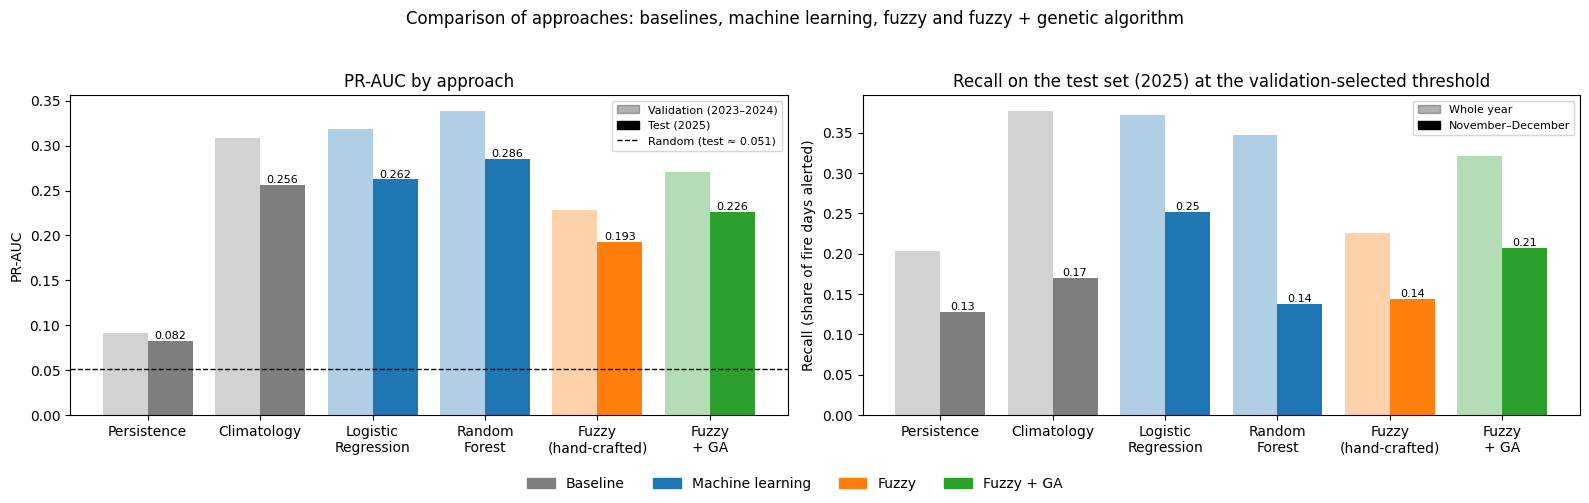

,model,family,PR-AUC (validation),PR-AUC (test),"recall (test, all year)","recall (test, Nov–Dec)"
0,Persistence,Baseline,0.092,0.082,0.203,0.128
1,Climatology,Baseline,0.308,0.256,0.377,0.170
2,Logistic Regression,Machine learning,0.318,0.262,0.372,0.252
3,Random Forest,Machine learning,0.339,0.286,0.347,0.137
4,Fuzzy (hand-crafted),Fuzzy,0.228,0.193,0.226,0.144
5,Fuzzy + GA,Fuzzy + GA,0.271,0.226,0.321,0.207


In [29]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

FAMILY_COLORS = {"Baseline": "tab:gray", "Machine learning": "tab:blue",
                 "Fuzzy": "tab:orange", "Fuzzy + GA": "tab:green"}

overview = [
    # name, family, validation scores, test scores, threshold
    ("Persistence", "Baseline", s_pers_val, test["fire_lag1"].values, 0.5),
    ("Climatology", "Baseline", s_clim_val, s_clim_test, val_thr["Climatology"]),
    ("Logistic\nRegression", "Machine learning", s_lr_val, s_lr_test, val_thr["Logistic Regression"]),
    ("Random\nForest", "Machine learning", s_rf_val, test_scores["All features"], ablation_thr["All features"]),
    ("Fuzzy\n(hand-crafted)", "Fuzzy", f_val, f_test, th_fuzzy),
    ("Fuzzy\n+ GA", "Fuzzy + GA", fga_val, fga_test, th_fga),
]

rows = []
for name, family, s_val, s_test, thr_ in overview:
    pred = (s_test >= thr_).astype(int)
    rows.append({
        "model": name.replace("\n", " "), "family": family,
        "PR-AUC (validation)": average_precision_score(y_val, s_val),
        "PR-AUC (test)": average_precision_score(yt, s_test),
        "recall (test, all year)": recall_score(yt, pred),
        "recall (test, Nov–Dec)": recall_score(yt[late], pred[late]),
    })
overview_df = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
x = np.arange(len(overview))
colors = [FAMILY_COLORS[f] for _, f, *_ in overview]
labels = [n for n, *_ in overview]

# Left: PR-AUC validation vs test
axes[0].bar(x - 0.2, overview_df["PR-AUC (validation)"], 0.4, color=colors, alpha=0.35, label="Validation (2023–2024)")
bars = axes[0].bar(x + 0.2, overview_df["PR-AUC (test)"], 0.4, color=colors, label="Test (2025)")
axes[0].bar_label(bars, fmt="%.3f", fontsize=8)
axes[0].axhline(yt.mean(), ls="--", color="black", lw=1, label=f"Random (test ≈ {yt.mean():.3f})")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_ylabel("PR-AUC")
axes[0].set_title("PR-AUC by approach")
axes[0].legend(handles=[Patch(color="black", alpha=0.3, label="Validation (2023–2024)"),
                        Patch(color="black", label="Test (2025)"),
                        Line2D([0], [0], ls="--", color="black", lw=1, label=f"Random (test ≈ {yt.mean():.3f})")],
               fontsize=8)

# Right: recall all year vs Nov–Dec (test)
axes[1].bar(x - 0.2, overview_df["recall (test, all year)"], 0.4, color=colors, alpha=0.35, label="Whole year")
bars = axes[1].bar(x + 0.2, overview_df["recall (test, Nov–Dec)"], 0.4, color=colors, label="November–December")
axes[1].bar_label(bars, fmt="%.2f", fontsize=8)
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_ylabel("Recall (share of fire days alerted)")
axes[1].set_title("Recall on the test set (2025) at the validation-selected threshold")
axes[1].legend(handles=[Patch(color="black", alpha=0.3, label="Whole year"),
                        Patch(color="black", label="November–December")],
               fontsize=8)

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLORS.values()]
fig.legend(handles, FAMILY_COLORS.keys(), loc="lower center", ncol=4, frameon=False)
plt.suptitle("Comparison of approaches: baselines, machine learning, fuzzy and fuzzy + genetic algorithm")
plt.tight_layout(rect=(0, 0.06, 1, 0.95))
plt.show()

overview_df.round(3)

**Interpretation.** Machine learning gives the best ranking of fire risk: the Random Forest has the highest PR-AUC
on both validation (0.339) and test (0.286). The hand-crafted fuzzy index is weaker but far above random, and tuning it
with the genetic algorithm raises its test PR-AUC by about 17% (0.193 to 0.226), reaching about 79% of the Random
Forest's PR-AUC while keeping nine readable rules; it remains below the climatology baseline (0.256).
The recall panel shows a different picture for the late season, when the 2025 fire season extended beyond its usual
pattern. The Random Forest, the most accurate model overall, is among the least robust there: its November–December
recall drops to 0.137, below climatology (0.170). Smoother models hold up better: logistic regression keeps the highest
late-season recall (0.252), followed by the GA-tuned fuzzy index (0.207), which relies on accumulated rainfall rather
than the calendar month. A plausible explanation (hypothesis) is that the Random Forest learns sharp, highly specific
seasonal and spatial patterns that fit typical years well but transfer poorly to an atypical season. Note that recall
values depend on each model's threshold (alert volume differs); PR-AUC remains the threshold-independent comparison.
There is therefore a trade-off between accuracy under typical conditions and robustness to an atypical season.

## 19. Walk-Forward Evaluation (Robustness Across Years)
The main test set covers a single year (2025). To check whether the conclusions hold in other years, the models are
re-evaluated with an expanding-window (walk-forward) scheme: for each year from 2021 to 2025, models are trained on
**all previous years only** and evaluated on that year. Training data therefore never include future information.
PR-AUC is used because it does not depend on a decision threshold. Same hyperparameters and seed as before.

The fuzzy indices are not included: their parameters were set with data from 2015–2022, so test years 2021–2022 would
not be out-of-sample for them. Note that the 2025 fold is trained on 2015–2024 (including the validation years), so
its values differ slightly from Section 14, where models were trained on 2015–2022.

In [30]:
RUN_WALK_FORWARD = True  # set False to skip during development (≈30 min)
WF_YEARS = [2021, 2022, 2023, 2024, 2025]
wf_rf = {"RF: All features": FEATURES, "RF: Context + Fire history": configs["Context + Fire history"]}

if RUN_WALK_FORWARD:
    wf_rows = []
    for year in WF_YEARS:
        start = time.time()
        tr, te = data[data["year"] < year], data[data["year"] == year]
        y_tr, y_te = tr["fire"], te["fire"]
        row = {"test year": year, "fire rate (random)": y_te.mean()}

        clim_wf = tr.groupby(["mun_key", "month"])["fire"].mean().rename("clim")
        s = te.join(clim_wf, on=["mun_key", "month"])["clim"].fillna(y_tr.mean()).values
        row["Climatology"] = average_precision_score(y_te, s)

        lr_wf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
        lr_wf.fit(tr[FEATURES], y_tr)
        row["Logistic Regression"] = average_precision_score(y_te, lr_wf.predict_proba(te[FEATURES])[:, 1])

        for name, feats in wf_rf.items():
            m = make_rf().fit(tr[feats], y_tr)
            row[name] = average_precision_score(y_te, m.predict_proba(te[feats])[:, 1])

        wf_rows.append(row)
        print(f"{year}: done in {time.time() - start:.0f} s", flush=True)

    wf = pd.DataFrame(wf_rows).set_index("test year")
    display(wf.round(3))
else:
    print("Walk-forward evaluation skipped (RUN_WALK_FORWARD = False).")

2021: done in 150 s
2022: done in 183 s
2023: done in 219 s
2024: done in 250 s
2025: done in 275 s


,fire rate (random),Climatology,Logistic Regression,RF: All features,RF: Context + Fire history
test year,,,,,
2021,0.045,0.317,0.366,0.380,0.382
2022,0.044,0.304,0.357,0.360,0.355
2023,0.051,0.336,0.344,0.370,0.358
2024,0.048,0.285,0.291,0.311,0.308
2025,0.051,0.260,0.262,0.290,0.278


,Climatology,Logistic Regression,RF: Context + Fire history,RF: All features
mean,0.300,0.324,0.336,0.342
std,0.029,0.045,0.042,0.039


,RF − Climatology,RF − Logistic Regression,Weather gain | context + fire
test year,,,
2021,0.062,0.013,-0.003
2022,0.056,0.003,0.005
2023,0.034,0.026,0.012
2024,0.026,0.019,0.002
2025,0.030,0.028,0.012


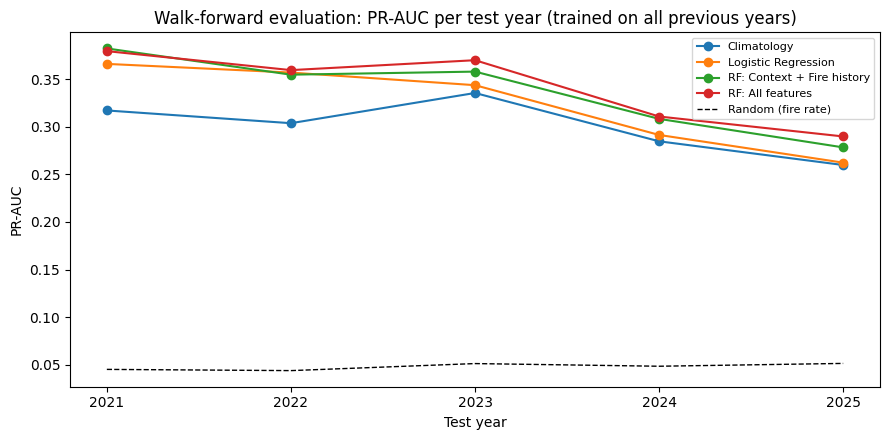

In [31]:
if RUN_WALK_FORWARD:
    models_wf = ["Climatology", "Logistic Regression", "RF: Context + Fire history", "RF: All features"]

    # Mean and standard deviation across the five years
    display(wf[models_wf].agg(["mean", "std"]).round(3))

    # Year-by-year differences
    diffs = pd.DataFrame({
        "RF − Climatology": wf["RF: All features"] - wf["Climatology"],
        "RF − Logistic Regression": wf["RF: All features"] - wf["Logistic Regression"],
        "Weather gain | context + fire": wf["RF: All features"] - wf["RF: Context + Fire history"],
    })
    display(diffs.round(3))

    fig, ax = plt.subplots(figsize=(9, 4.5))
    for name in models_wf:
        ax.plot(wf.index, wf[name], marker="o", label=name)
    ax.plot(wf.index, wf["fire rate (random)"], ls="--", color="black", lw=1, label="Random (fire rate)")
    ax.set_xticks(WF_YEARS)
    ax.set_title("Walk-forward evaluation: PR-AUC per test year (trained on all previous years)")
    ax.set_xlabel("Test year")
    ax.set_ylabel("PR-AUC")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

**Interpretation.** The walk-forward evaluation confirms the main conclusions beyond the single test year. The Random
Forest outperformed climatology in all five years (+0.026 to +0.062) and logistic regression in all five years (+0.003
to +0.028), with mean PR-AUC of 0.342 ± 0.039 against 0.300 ± 0.029 and 0.324 ± 0.045, respectively. The gain from
weather once fire history is known was positive in four of the five years but always small (−0.003 to +0.012),
consistent with the ablation study. All models declined in 2024–2025, consistent with a shift in fire behavior in
recent years. The 2025 fold (trained on 2015–2024) gives a Random Forest PR-AUC of 0.290, close to the 0.286 of the
main evaluation (trained on 2015–2022).

## 20. Conclusions

**Summary of performance (test set, 2025; random classifier PR-AUC ≈ 0.051).** The full Random Forest was the best model
(PR-AUC 0.286), followed by the Random Forest with context and fire history (0.274), logistic regression (0.262),
climatology (0.256), the GA-tuned fuzzy index (0.226), the hand-crafted fuzzy index (0.193) and persistence (0.082).
At the threshold selected on validation, the Random Forest detected 35% of the fire days (1,454 of 4,191), with about
two false alarms per correct alert. All models performed worse in 2025 than in validation, by a similar proportion,
which points to a harder test year rather than overfitting.

**Answer to the research question.** At the municipality-day scale and with these data, weather variables add little
predictive power beyond location, season and recent fire activity. The ablation study showed that adding weather to
context alone *reduced* PR-AUC, while recent fire activity (`fire_7d`) explained most of the gain over climatology;
weather added a small but consistent gain once fire history was known (confirmed across five random seeds and on the
test set). Regarding the secondary question, nine interpretable fuzzy rules reached about two thirds of the Random
Forest's PR-AUC, and about 79% after tuning by a genetic algorithm, at the cost of less intuitive fuzzy sets.

**Main limitations.**
- The models behave mainly as detectors of *continuing* fire activity: new outbreaks (32% of the fire days in 2025)
  were almost never anticipated (Random Forest recall 0.4%), and no model ranked them well.
- Performance depends on the usual seasonal pattern: when the 2025 season extended into November–December, the
  Random Forest's recall dropped sharply (0.137). Smoother models coped better with this late season (logistic
  regression 0.252; GA-tuned fuzzy index 0.207), revealing a trade-off between accuracy in typical years and
  robustness to atypical seasons.
- Label noise (undetected fires), the coarse resolution of the weather data and the absence of human and land-use
  drivers limit what can be predicted. The main test set covers a single year; Section 19 complements it with a multi-year walk-forward evaluation.

**Risks and possible biases.** A single statewide threshold favored the Cerrado (recall 54%) over the Caatinga
(recall 24%), although the Caatinga concentrated 65% of the fire days. If used operationally, such a model could
concentrate attention where fires are already active and give a false sense of security in municipalities without
recent fires; it should support, not replace, expert judgment and existing fire-danger products. Predicted
probabilities are not calibrated and should be read as a ranking of risk.

**Next steps.** (i) Assess robustness with a more sensitive fire product (VIIRS, 375 m) and quantify label noise;
(ii) use region- or biome-specific thresholds; (iii) add human and land-use variables (e.g., land cover, agricultural
calendar); (iv) build a dedicated model for new outbreaks; (v) calibrate probabilities; (vi) learn fuzzy parameters
with wider, constrained bounds or ANFIS, balancing accuracy and interpretability.

## 21. Use of Large Language Models

A large language model was used during this project: **Claude (Anthropic)**, through the claude.ai chat interface.

**Purposes.** Brainstorming and comparison of candidate topics; suggestions of public data sources; discussion of the
experimental design (temporal split, leakage prevention, metrics for imbalanced data, ablation study, stability
analysis); debugging of execution
errors; explanations of concepts (Random Forest, PR-AUC vs ROC-AUC, fuzzy inference, genetic algorithms).

**Representative prompts (paraphrased).** "Why use PR-AUC instead of ROC-AUC?"; "Explain how a Random Forest works".

**Verification.** All code was executed by the author in Google Colab; outputs (row counts, missing values, metrics)
were checked against expected values at each step; The LLM is not cited as a scientific source; data
and methods are attributed to their original authors. The author remains responsible for all content.

## 22. References

- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32.
- Holland, J. H. (1975). *Adaptation in Natural and Artificial Systems*. University of Michigan Press.
- INPE – Instituto Nacional de Pesquisas Espaciais. Programa Queimadas – BDQueimadas. www.inpe.br/queimadas/bdqueimadas
- Mamdani, E. H.; Assilian, S. (1975). An experiment in linguistic synthesis with a fuzzy logic controller.
  *International Journal of Man-Machine Studies*, 7(1), 1–13.
- NASA Langley Research Center. POWER Project — Prediction Of Worldwide Energy Resources. power.larc.nasa.gov
- Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Saito, T.; Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating
  binary classifiers on imbalanced datasets. *PLoS ONE*, 10(3), e0118432.
- Zadeh, L. A. (1965). Fuzzy sets. *Information and Control*, 8(3), 338–353.